<a href="https://colab.research.google.com/github/njoh0025/MMA3001-Nicholas-Johnson/blob/main/Nicholas%20Johnson%20Assignment%20Source%20Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# --- Combined Workspace: Merged Occupancy Analysis & Interactive Tools ---

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPRegressor
from IPython.display import display, HTML

# Configure standard seaborn visualization aesthetic for clear graphs
sns.set_theme(style="whitegrid")

# =========================================================================
# 1. Loading & Standardizing Datasets (Pre and Post Daylight Savings)
# =========================================================================
"""
This section handles loading multiple sequential Excel spreadsheets containing historical sensor data,
automatically detecting header rows if metadata headers are present, and standardizing varied column schemas
into unified database keys (collecteddate, floorspaceid, headcount).
"""
start_time = time.time()
files = ['Pre Daylight Savings 1.xlsx', 'Pre Daylight Savings 2.xlsx', 'Post Daylight Savings.xlsx']
dfs = []

for file_name in files:
    print(f"Loading Excel file: {file_name}...")
    excel_file = pd.ExcelFile(file_name)
    sheet_name = excel_file.sheet_names[0]
    temp_df = excel_file.parse(sheet_name)

    # Fallback to automatically skip metadata header rows if the first parse returns empty
    if temp_df.empty or len(temp_df.columns) == 0:
        print(f"First parse attempt for {file_name} was empty. Automatically locating the header row...")
        for skiprows in range(1, 10):
            temp_df = excel_file.parse(sheet_name, skiprows=skiprows)
            if not temp_df.empty and len(temp_df.columns) > 0:
                break

    # Standardize and strip quote anomalies and whitespace from header string names
    temp_df.columns = temp_df.columns.astype(str).str.replace('"', '', regex=False).str.strip()
    col_map = {c.lower().replace(" ", "").replace("_", ""): c for c in temp_df.columns}

    # Map schema variations to target database columns
    target_cols = {
        'collecteddate': col_map.get('collecteddate'),
        'floorspaceid': col_map.get('floorspaceid'),
        'headcount': col_map.get('headcount')
    }

    # Extended fallback column-name search looking for substrings
    for standard_name, mapped_name in target_cols.items():
        if mapped_name is None:
            for col in temp_df.columns:
                clean_col = col.lower().replace(" ", "").replace("_", "")
                if standard_name in clean_col:
                    target_cols[standard_name] = col
                    break

    missing = [k for k, v in target_cols.items() if v is None]
    if missing:
        raise KeyError(f"Could not find suitable columns in {file_name} for: {missing}.")

    temp_df = temp_df.rename(columns={v: k for k, v in target_cols.items() if v is not None})
    dfs.append(temp_df)

# Combine and run standard character replacements on text columns
df = pd.concat(dfs, ignore_index=True)
print("Combined dataset size:", df.shape[0])

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.replace('"', '', regex=False).str.strip()

# Ensure headcount is numerical and strip missing targets/timestamps
df['headcount'] = pd.to_numeric(df['headcount'], errors='coerce')
df = df.dropna(subset=['collecteddate', 'floorspaceid', 'headcount'])

Loading Excel file: Pre Daylight Savings 1.xlsx...
Loading Excel file: Pre Daylight Savings 2.xlsx...
Loading Excel file: Post Daylight Savings.xlsx...
Combined dataset size: 1048575


Converting dates to local Victoria time...

--- Individual Room Occupancy Statistics ---


,Room,Mean Occupancy,Standard Deviation (Std),Max Occupancy,Min Occupancy
0,Room A,2.196044,1.710558,25,0
1,Room B,4.105876,3.854917,38,0
2,Room C,7.432215,4.055343,25,0
3,Room D,2.319945,1.509078,14,0
4,Room E,3.073506,3.600397,49,0


--------------------------------------------

Training HistGradientBoosting model...
Training Mean Error (Actual - Predicted): -0.0010
Validation Mean Error (Actual - Predicted): -0.0039


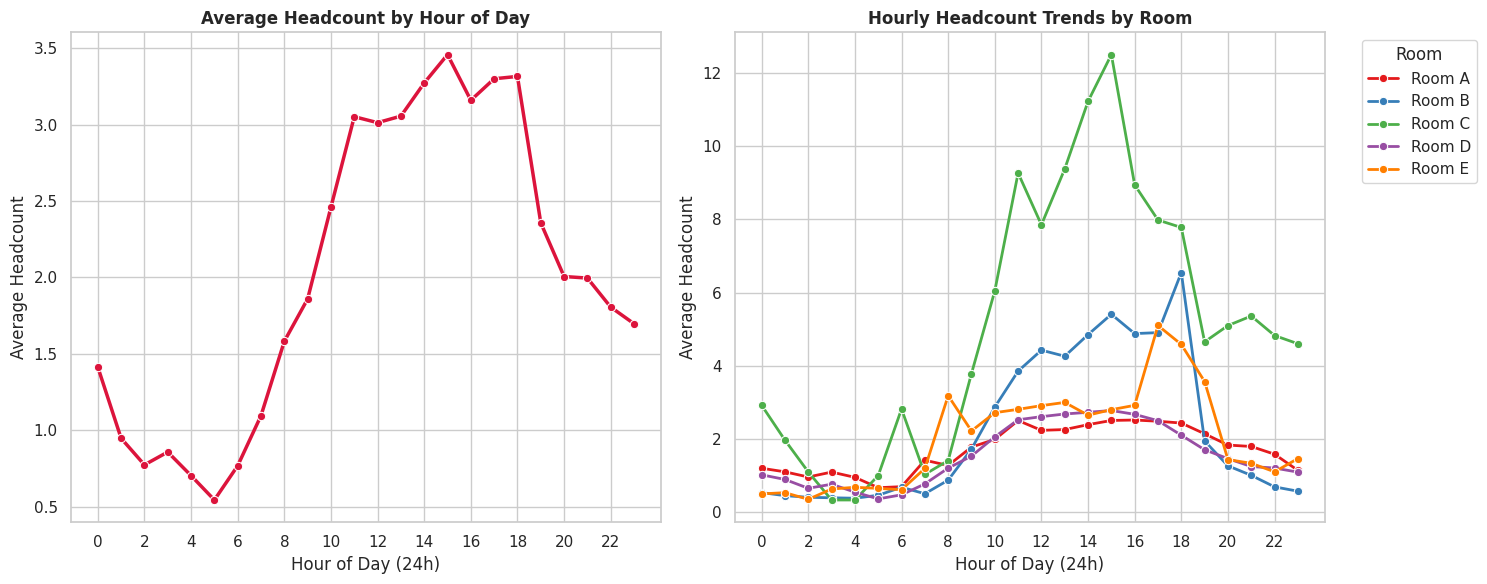

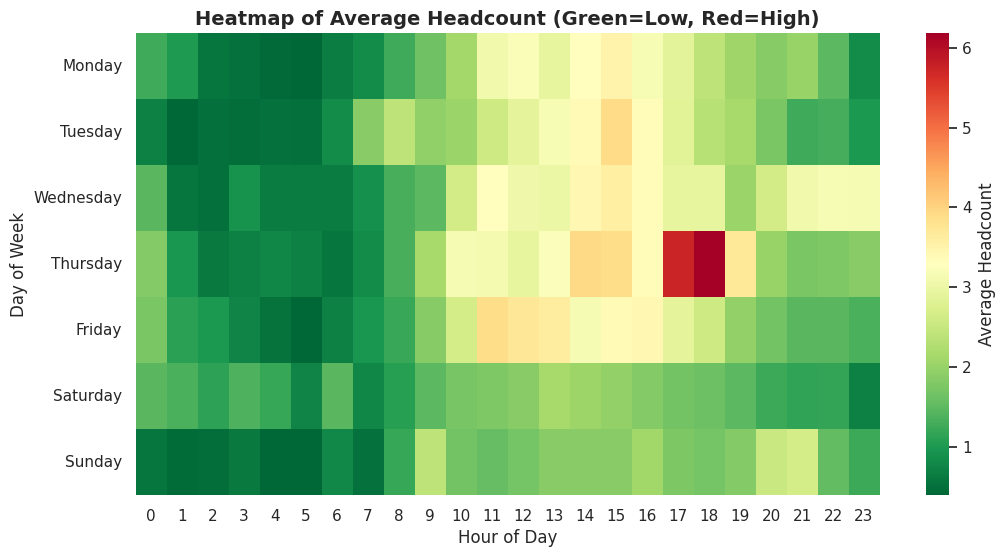

Generating 30-minute interval database & running NN imputation...
Integrated MLP NN (30-Min) Training Mean Error (Actual - Predicted): 0.046610
30-Minute Grid Unified Imputation complete.

--- Interactive Lookup Tool Ready ---


Merged workspace configured in 174.56 seconds.


In [3]:
# =========================================================================
# 2. Rename Room UUIDs & Local Timezone Conversion
# =========================================================================
room_mapping = {
    '0f3f37f8-0335-41e0-ae87-a1d677dfc7d7': 'Room A',
    '227f1068-9e41-469f-bef0-275f27a0bdba': 'Room B',
    '3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8': 'Room C',
    '941f0352-bb69-47d0-a9c5-ac29eb4f7319': 'Room D',
    'cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b': 'Room E'
}
df['floorspaceid'] = df['floorspaceid'].map(room_mapping).fillna(df['floorspaceid'])

print("Converting dates to local Victoria time...")
df['collecteddate'] = pd.to_datetime(df['collecteddate'], errors='coerce', utc=True)
df = df.dropna(subset=['collecteddate'])
df['collecteddate_local'] = df['collecteddate'].dt.tz_convert('Australia/Melbourne')

# Extract temporal and cycle features for regression models
df['timestamp'] = df['collecteddate'].astype(np.int64) // 10**9
df['hour'] = df['collecteddate_local'].dt.hour
df['dayofweek'] = df['collecteddate_local'].dt.dayofweek

# Calculate and Display Room Occupancy Statistics including Standard Deviation (Variability)
print("\n--- Individual Room Occupancy Statistics ---")
room_stats = df.groupby('floorspaceid')['headcount'].agg(['mean', 'std', 'max', 'min']).reset_index()
room_stats.columns = ['Room', 'Mean Occupancy', 'Standard Deviation (Std)', 'Max Occupancy', 'Min Occupancy']
display(room_stats)
print("--------------------------------------------\n")

# =========================================================================
# 3. Model 1: HistGradientBoostingRegressor (Supervised Learning model)
# =========================================================================
le = LabelEncoder()
df['floorspaceid_encoded'] = le.fit_transform(df['floorspaceid'])

features = ['floorspaceid_encoded', 'timestamp', 'hour', 'dayofweek']
target = 'headcount'

# Sub-sample evaluation mask using modulo mapping to preserve timeline sequencing
validation_mask = df.index % 5 == 0
train_df = df[~validation_mask]
val_df = df[validation_mask]

print("Training HistGradientBoosting model...")
hgb_model = HistGradientBoostingRegressor(random_state=42)
hgb_model.fit(train_df[features], train_df[target])

# Calculate out-of-sample validation quality indicator (Mean Error)
predictions_train = hgb_model.predict(train_df[features])
train_mean_error = np.mean(train_df[target] - predictions_train)
print(f"Training Mean Error (Actual - Predicted): {train_mean_error:.4f}")

predictions = hgb_model.predict(val_df[features])
mean_error = np.mean(val_df[target] - predictions)
print(f"Validation Mean Error (Actual - Predicted): {mean_error:.4f}")

# =========================================================================
# 4. Exploratory Visualizations & Heatmaps
# =========================================================================
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
houly_trends = df.groupby('hour')['headcount'].mean().reset_index()
sns.lineplot(data=houly_trends, x='hour', y='headcount', marker='o', color='crimson', linewidth=2.5)
plt.title('Average Headcount by Hour of Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (24h)')
plt.ylabel('Average Headcount')
plt.xticks(range(0, 24, 2))

plt.subplot(1, 2, 2)
room_hourly = df.groupby(['hour', 'floorspaceid'])['headcount'].mean().reset_index()
sns.lineplot(data=room_hourly, x='hour', y='headcount', hue='floorspaceid', marker='o', palette='Set1', linewidth=2)
plt.title('Hourly Headcount Trends by Room', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (24h)')
plt.ylabel('Average Headcount')
plt.xticks(range(0, 24, 2))
plt.legend(title='Room', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Global Hour-Day Weekly Occupancy Heatmap with high-contrast palette
plt.figure(figsize=(12, 6))
pivot_table = df.pivot_table(values='headcount', index='dayofweek', columns='hour', aggfunc='mean')
day_labels = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_table.index = [day_labels[i] for i in pivot_table.index]
sns.heatmap(pivot_table, cmap='RdYlGn_r', annot=False, cbar_kws={'label': 'Average Headcount'})
plt.title('Heatmap of Average Headcount (Green=Low, Red=High)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.show()

# =========================================================================
# 5. Combined Model 2: Neural Network 30-Minute Grid Imputation Setup
# =========================================================================
print("Generating 30-minute interval database & running NN imputation...")
rooms = sorted(df['floorspaceid'].unique())
df['half_hour'] = df['collecteddate_local'].dt.hour + (df['collecteddate_local'].dt.minute >= 30) * 0.5

# Extract baseline statistics and averages
occupancy_base = df.groupby(['floorspaceid', 'dayofweek', 'half_hour'])['headcount'].mean().reset_index()
half_hours = [x * 0.5 for x in range(48)]

# Generate coordinates (5 rooms x 7 days x 48 slots = 1,680 records)
full_idx = pd.MultiIndex.from_product([rooms, range(7), half_hours], names=['floorspaceid', 'dayofweek', 'half_hour'])
full_df = pd.DataFrame(index=full_idx).reset_index()
full_df = pd.merge(full_df, occupancy_base, on=['floorspaceid', 'dayofweek', 'half_hour'], how='left')

room_time_avg = df.groupby(['floorspaceid', 'half_hour'])['headcount'].mean().reset_index().rename(columns={'headcount': 'room_time_avg'})
full_df = pd.merge(full_df, room_time_avg, on=['floorspaceid', 'half_hour'], how='left').fillna({'room_time_avg': 0})

other_rooms_day_avg = df.groupby(['dayofweek', 'floorspaceid'])['headcount'].mean().unstack()
other_busyness_map = {(r, d): other_rooms_day_avg.loc[d].drop(r, errors='ignore').mean() for r in rooms for d in range(7)}
full_df['other_busyness'] = full_df.apply(lambda row: other_busyness_map.get((row['floorspaceid'], row['dayofweek']), 0), axis=1).fillna(0)

train_set_30 = full_df.dropna(subset=['headcount'])
test_set_30 = full_df[full_df['headcount'].isna()]
full_df['imputed_headcount'] = full_df['headcount']

# Train single, integrated MLP network directly on the 30-minute grid
if not train_set_30.empty:
    scaler_30 = StandardScaler()
    features_cols = ['dayofweek', 'half_hour', 'room_time_avg', 'other_busyness']
    X_train_30 = scaler_30.fit_transform(train_set_30[features_cols])

    mlp_30 = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', max_iter=1000, random_state=42)
    mlp_30.fit(X_train_30, train_set_30['headcount'])

    # Calculate and display the integrated model performance metrics
    predictions_train_30 = mlp_30.predict(X_train_30)
    mean_train_error_30 = np.mean(train_set_30['headcount'] - predictions_train_30)
    print(f"Integrated MLP NN (30-Min) Training Mean Error (Actual - Predicted): {mean_train_error_30:.6f}")

    if not test_set_30.empty:
        X_test_30 = scaler_30.transform(test_set_30[features_cols])
        predictions_30 = mlp_30.predict(X_test_30)
        full_df.loc[full_df['headcount'].isna(), 'imputed_headcount'] = np.maximum(0, predictions_30)

print("30-Minute Grid Unified Imputation complete.")

# =========================================================================
# 6. Simpson's Integration & Interactive Lookup Tool
# =========================================================================
def simpsons_rule_integration(y, h=0.5):
    """Calculates integration of y values with interval spacing h using Simpson's 1/3 rule."""
    n = len(y) - 1
    if n == 0:
        return 0.0
    if n % 2 != 0:
        integral = (h / 3) * (y[0] + y[n-1] + 4 * sum(y[1:n-1:2]) + 2 * sum(y[2:n-2:2]))
        integral += (h / 2) * (y[n-1] + y[n])
    else:
        integral = (h / 3) * (y[0] + y[n] + 4 * sum(y[1:n:2]) + 2 * sum(y[2:n:2]))
    return integral

def format_half_hour_label(val):
    h = int(val)
    m = "30" if (val % 1 == 0.5) else "00"
    return f"{h:02d}:{m}"

time_options = [(format_half_hour_label(x * 0.5), x * 0.5) for x in range(49)]

# Render interactive widgets for the calculator interface
room_dropdown = widgets.Dropdown(options=rooms, description='Room:')
day_dropdown = widgets.Dropdown(options=day_labels, description='Day:')
start_time_dropdown = widgets.Dropdown(options=time_options[:-1], value=8.0, description='Start Time:')
end_time_dropdown = widgets.Dropdown(options=time_options[1:], value=18.0, description='End Time:')

def update_end_time(*args):
    if end_time_dropdown.value <= start_time_dropdown.value:
        end_time_dropdown.value = min(24.0, start_time_dropdown.value + 0.5)

start_time_dropdown.observe(update_end_time, 'value')
output_label = widgets.Output()

def calculate_occupancy_on_click(b):
    with output_label:
        output_label.clear_output()
        r = room_dropdown.value
        d_idx = day_labels.index(day_dropdown.value)
        t_start = start_time_dropdown.value
        t_end = end_time_dropdown.value

        if t_end <= t_start:
            print("Error: End time must be greater than start time.")
            return

        subset = full_df[(full_df['floorspaceid'] == r) &
                         (full_df['dayofweek'] == d_idx) &
                         (full_df['half_hour'] >= t_start) &
                         (full_df['half_hour'] <= t_end)].sort_values('half_hour')

        y_vals = subset['imputed_headcount'].values
        if len(y_vals) < 2:
            print("Not enough data points selected for numerical integration.")
            return

        total_occupancy_hours = simpsons_rule_integration(y_vals, h=0.5)
        print(f"Selected Interval: {format_half_hour_label(t_start)} to {format_half_hour_label(t_end)}")
        print(f"Estimated Cumulative Occupancy (Person-Hours) via Simpson's 1/3 Rule: {total_occupancy_hours:.3f} person-hours")

calc_button = widgets.Button(description="Calculate Occupancy", button_style='primary')
calc_button.on_click(calculate_occupancy_on_click)

print("\n--- Interactive Lookup Tool Ready ---")
display(widgets.VBox([room_dropdown, day_dropdown, start_time_dropdown, end_time_dropdown, calc_button, output_label]))
print(f"Merged workspace configured in {time.time() - start_time:.2f} seconds.")

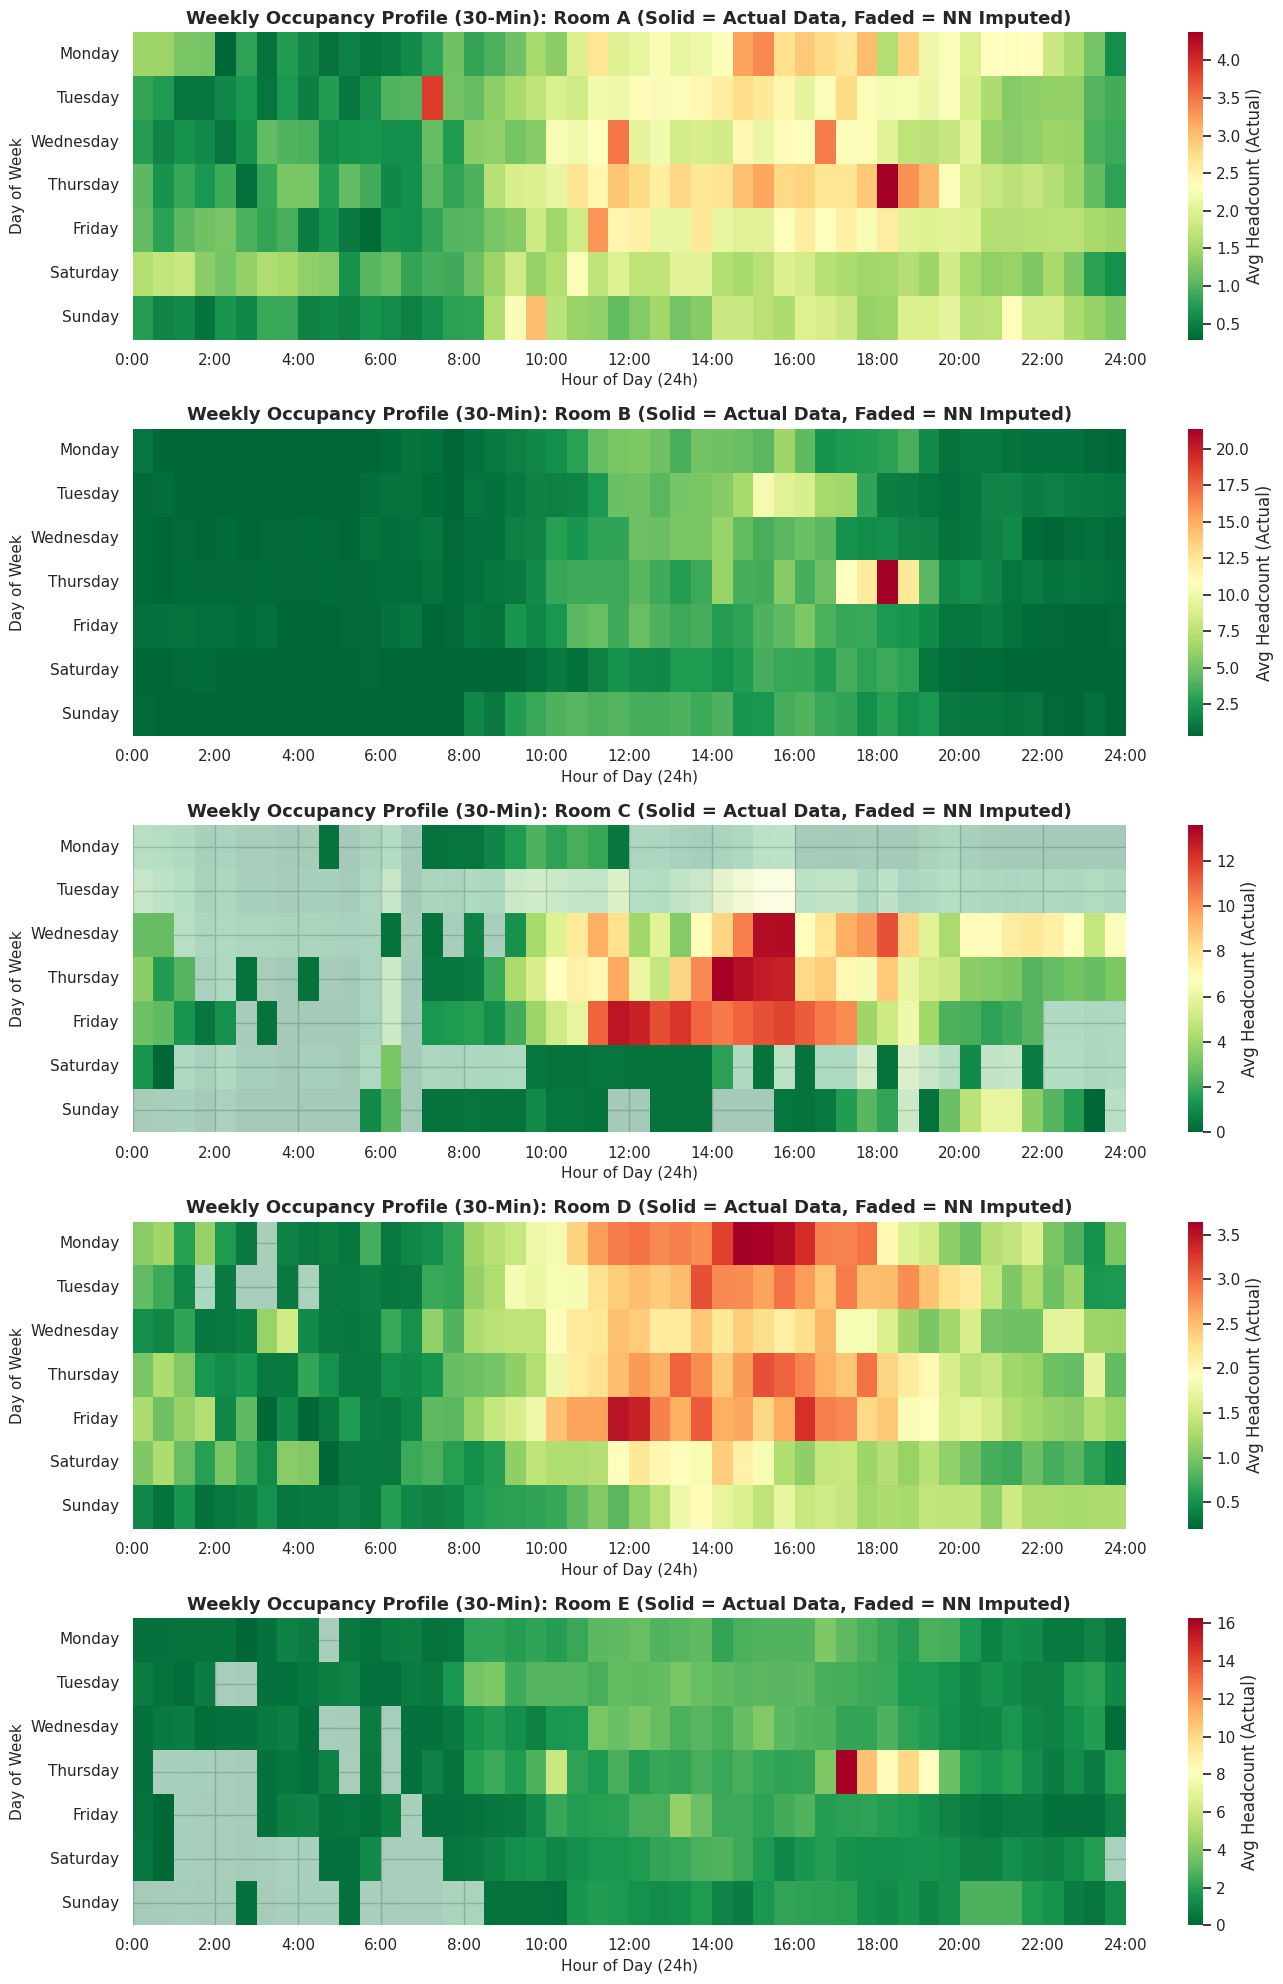

In [4]:
# --- Room-by-Room Occupancy Heatmaps (Distinguishing Predictions with Unified Color Scales) ---

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import warnings

# Define the labels for the visualizations
rooms = ['Room A', 'Room B', 'Room C', 'Room D', 'Room E']
day_labels = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Configure global Seaborn parameters for consistent aesthetics
sns.set_theme(style="whitegrid")

# Setup a vertical grid containing 5 subplots (one for each room)
fig, axes = plt.subplots(len(rooms), 1, figsize=(14, 4 * len(rooms)), sharex=False)
if len(rooms) == 1:
    axes = [axes]

for idx, room_id in enumerate(rooms):
    """
    Construct individual occupancy heatmap visualizations for each floor space.
    This layout separates recorded sensor data from neural network predictions using a dual-layered plot.
    Observed metrics display opaque, high-density colors. Imputed missing values are represented with semi-transparent indicators.
    """
    ax = axes[idx]

    # Generate base 7x48 grids for actual observed values vs machine-learned estimates (30-minute intervals)
    grid_actual = np.full((7, 48), np.nan)
    grid_estimated = np.full((7, 48), np.nan)

    # Slice out 30-minute database records for the current room
    room_data = full_df[full_df['floorspaceid'] == room_id]

    for _, row in room_data.iterrows():
        d = int(row['dayofweek'])
        # Map half_hour (0.0 to 23.5) to an index from 0 to 47
        h_idx = int(row['half_hour'] * 2)
        if not np.isnan(row['headcount']):
            grid_actual[d, h_idx] = row['headcount']
        else:
            # Use predicted value as the machine learning estimate where no baseline exists
            grid_estimated[d, h_idx] = row['imputed_headcount'] if not np.isnan(row['imputed_headcount']) else 0

    # Combine actual and estimated values to find consistent min/max limits for a unified color scale
    combined_grid = np.where(np.isnan(grid_actual), grid_estimated, grid_actual)
    valid_values = combined_grid[~np.isnan(combined_grid)]

    if len(valid_values) > 0:
        vmin = np.nanmin(valid_values)
        vmax = np.nanmax(valid_values)
    else:
        vmin, vmax = None, None

    # Render the primary heatmap containing only actual empirical headcounts (Solid colours)
    if not np.isnan(grid_actual).all():
        sns.heatmap(                    grid_actual,
            cmap='RdYlGn_r',
            annot=False,
            vmin=vmin,
            vmax=vmax,
            cbar_kws={'label': 'Avg Headcount (Actual)'},
            ax=ax,
            yticklabels=day_labels
        )

    # Superimpose machine-learned estimates with high transparency (alpha=0.35) sharing the exact same color bounds
    if not np.isnan(grid_estimated).all():
        sns.heatmap(                    grid_estimated,
            cmap='RdYlGn_r',
            annot=False,
            alpha=0.35,
            vmin=vmin,
            vmax=vmax,
            cbar=False,
            ax=ax,
            yticklabels=day_labels
        )

    ax.set_title(f'Weekly Occupancy Profile (30-Min): {room_id} (Solid = Actual Data, Faded = NN Imputed)', fontsize=13, fontweight='bold')
    ax.set_ylabel('Day of Week', fontsize=11)

    # Configure x-axis timescale ticks for every subplot individually
    ax.set_xticks(np.arange(0, 49, 4))
    ax.set_xticklabels([f"{int(x * 0.5)}:00" for x in np.arange(0, 49, 4)], rotation=0)
    ax.set_xlabel('Hour of Day (24h)', fontsize=11)

plt.tight_layout()
plt.show()

In [6]:
import pytest
import numpy as np
import sys
import os

# Writing pytest test cases to a temporary file
test_code = """
import numpy as np
import pytest
from sklearn.preprocessing import StandardScaler

# Import functions to be tested from the global state or redefine them cleanly for verification
def simpsons_rule_integration(y, h=0.5):
    n = len(y) - 1
    if n == 0:
        return 0.0
    if n % 2 != 0:
        integral = (h / 3) * (y[0] + y[n-1] + 4 * sum(y[1:n-1:2]) + 2 * sum(y[2:n-2:2]))
        integral += (h / 2) * (y[n-1] + y[n])
    else:
        integral = (h / 3) * (y[0] + y[n] + 4 * sum(y[1:n:2]) + 2 * sum(y[2:n:2]))
    return integral

def test_simpsons_rule_constant_function():
    # Integrating a constant function f(x) = 5 over [0, 2] with h=0.5
    y = np.array([5.0, 5.0, 5.0, 5.0, 5.0])
    result = simpsons_rule_integration(y, h=0.5)
    expected = 5.0 * 2.0
    assert np.isclose(result, expected), f"Expected {expected}, but got {result}"

def test_simpsons_rule_linear_function():
    # Integrating f(x) = 2x over [0, 2] with h=0.5. Analytical solution is x^2 | 0 to 2 = 4
    # x = [0, 0.5, 1.0, 1.5, 2.0], y = [0, 1.0, 2.0, 3.0, 4.0]
    y = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
    result = simpsons_rule_integration(y, h=0.5)
    expected = 4.0
    assert np.isclose(result, expected), f"Expected {expected}, but got {result}"

def test_simpsons_rule_odd_length():
    # Testing Simpson's rule fallback logic when the number of subintervals (n) is odd (i.e., len(y) is even)
    # f(x) = 2 over [0, 1.5] with h=0.5. Expected integral = 3.0
    y = np.array([2.0, 2.0, 2.0, 2.0])
    result = simpsons_rule_integration(y, h=0.5)
    expected = 3.0
    assert np.isclose(result, expected), f"Expected {expected}, but got {result}"

def test_simpsons_rule_single_point():
    # Single data point should yield 0.0
    y = np.array([5.0])
    result = simpsons_rule_integration(y, h=0.5)
    assert result == 0.0, f"Expected 0.0, but got {result}"
"""

with open('test_workspace.py', 'w') as f:
    f.write(test_code)

print("Running pytest on workspace tests...\n")
# Run pytest from within the notebook session and capture the output
pytest.main(["-v", "test_workspace.py"])

Running pytest on workspace tests...

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collecting ... collected 4 items

test_workspace.py::test_simpsons_rule_constant_function PASSED           [ 25%]
test_workspace.py::test_simpsons_rule_linear_function PASSED             [ 50%]
test_workspace.py::test_simpsons_rule_odd_length PASSED                  [ 75%]
test_workspace.py::test_simpsons_rule_single_point PASSED                [100%]

============================== 4 passed in 0.04s ===============================


<ExitCode.OK: 0>